# 01. Exploratory Data Analysis & Domain Audit — California Housing

This notebook audits the **California Housing Dataset** (1990 US Census block groups, $N = 20,640$) to inspect schema integrity, right-censoring boundaries, structural anomalies, spatial correlations, and domain relationships prior to building our geospatial feature engineering pipeline.


In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.config import DATA_DIR, FIGURES_DIR
from src.data_loader import inspect_data_quality, load_california_housing_data
from src.features import CALIFORNIA_COASTLINE_POINTS, haversine_distance_km

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)


We import our centralized `src.data_loader` and `src.features` utilities so notebook exploration stays synchronized with the production training pipeline.

In [2]:
df, raw_features, target_col = load_california_housing_data(DATA_DIR)
quality = inspect_data_quality(df)

print(f"Rows: {quality['n_rows']:,} | Columns: {quality['n_columns']}")
print(f"Missing Values: {quality['total_missing']} | Duplicate Rows: {quality['duplicate_rows']}")
print(f"Right-Censored Target (>= $500k): {quality['target_capped_count']} ({quality['target_capped_pct']:.2f}%)")
print(f"Age-Capped (>= 52 yrs): {quality['age_capped_count']} ({quality['age_capped_pct']:.2f}%)")
print(
    f"Structural Outliers -> AveRooms > 20: {quality['extreme_ave_rooms_gt_20']} | "
    f"AveBedrms > 5: {quality['extreme_ave_bedrms_gt_5']} | AveOccup > 15: {quality['extreme_ave_occup_gt_15']}"
)
df.head()


Rows: 20,640 | Columns: 9
Missing Values: 0 | Duplicate Rows: 0
Right-Censored Target (>= $500k): 992 (4.81%)
Age-Capped (>= 52 yrs): 1273 (6.17%)
Structural Outliers -> AveRooms > 20: 69 | AveBedrms > 5: 45 | AveOccup > 15: 19


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


### Data Quality & Domain Audit Findings
- **Zero Missing / Zero Duplicates**: All 20,640 census block groups are complete across all 8 numerical predictors and target `MedHouseVal`.
- **Target Censoring (`MedHouseVal >= 5.0`)**: Nearly 5% of census blocks are top-coded at `$500,001`. This artificial ceiling introduces heteroscedastic compression at the upper tail and motivates our later **slice-based error analysis** separating censored vs. uncensored homes.
- **Extreme Block Outliers**: Small subsets of block groups exhibit extreme `AveRooms` or `AveOccup` (e.g., institutional housing, student dormitories, or hotels). Adding log-compressed volume features (`LogPopulation`, `LogAveOccup`) stabilizes linear baselines without discarding real observations.


In [3]:
df.describe().T[["count", "mean", "std", "min", "50%", "max"]]

,count,mean,std,min,50%,max
MedInc,20640.0,3.870671,1.899822,0.499900,3.534800,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,29.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,5.229129,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.048780,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,1166.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.818116,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,34.260000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-118.490000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.797000,5.000010


The summary table confirms wide scale differences (`Population` up to 35,682 vs. `AveBedrms` median ~1.05), reinforcing why `StandardScaler` (fitted strictly on the training split) is essential for linear and distance-aware models.

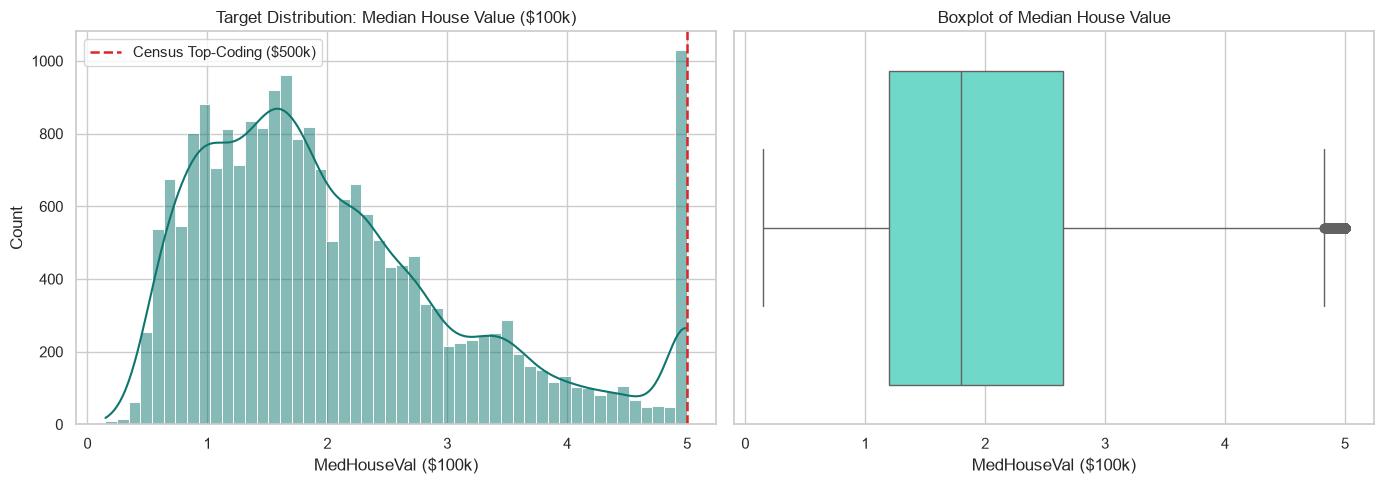

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["MedHouseVal"], bins=50, kde=True, color="#0f766e", ax=axes[0])
axes[0].axvline(5.0, color="#dc2626", linestyle="--", lw=1.8, label="Census Top-Coding ($500k)")
axes[0].set_title("Target Distribution: Median House Value ($100k)")
axes[0].set_xlabel("MedHouseVal ($100k)")
axes[0].legend()

sns.boxplot(x=df["MedHouseVal"], color="#5eead4", ax=axes[1])
axes[1].set_title("Boxplot of Median House Value")
axes[1].set_xlabel("MedHouseVal ($100k)")

plt.tight_layout()
plt.show()


### Target Variable Inspection
The histogram highlights a right-skewed distribution centered around `$179,700` (median) with a distinct artificial spike at `$5.0` (`$500,000+`) from survey censoring.

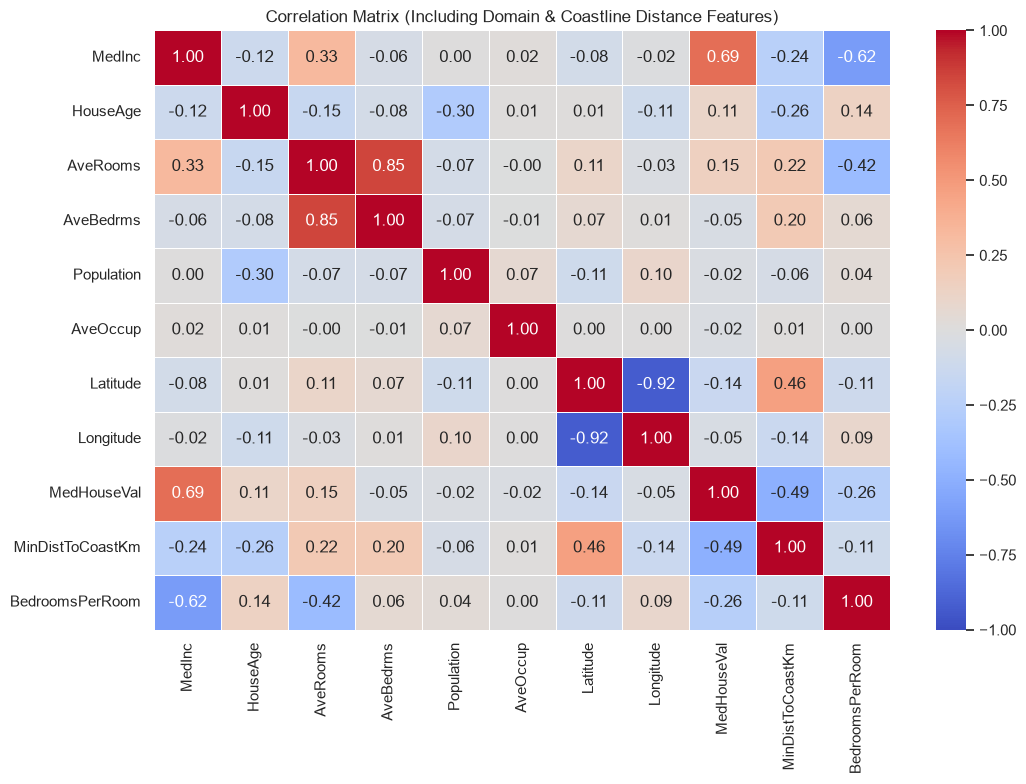

In [5]:
lat = df["Latitude"].to_numpy()
lon = df["Longitude"].to_numpy()
coast_km = np.min(
    np.vstack([haversine_distance_km(lat, lon, clat, clon) for clat, clon in CALIFORNIA_COASTLINE_POINTS]),
    axis=0,
)
df_eda = df.copy()
df_eda["MinDistToCoastKm"] = coast_km
df_eda["BedroomsPerRoom"] = df_eda["AveBedrms"] / np.clip(df_eda["AveRooms"], 0.5, None)

plt.figure(figsize=(11, 8))
sns.heatmap(df_eda.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.4)
plt.title("Correlation Matrix (Including Domain & Coastline Distance Features)")
plt.tight_layout()
plt.show()


### Key Correlation Insights
1. **`MedInc` ($r = 0.69$)**: Median income remains the strongest positive univariate predictor.
2. **`MinDistToCoastKm` (Negative correlation)**: Proximity to the Pacific coast strongly separates premium coastal metros from inland valleys — validating our Haversine coastline engineering.
3. **Collinearity (`AveRooms` vs `AveBedrms`, $r = 0.85$)**: Engineering `BedroomsPerRoom` isolates housing typology (luxury large homes vs. dense multi-bedroom apartments) and reduces redundant collinearity.


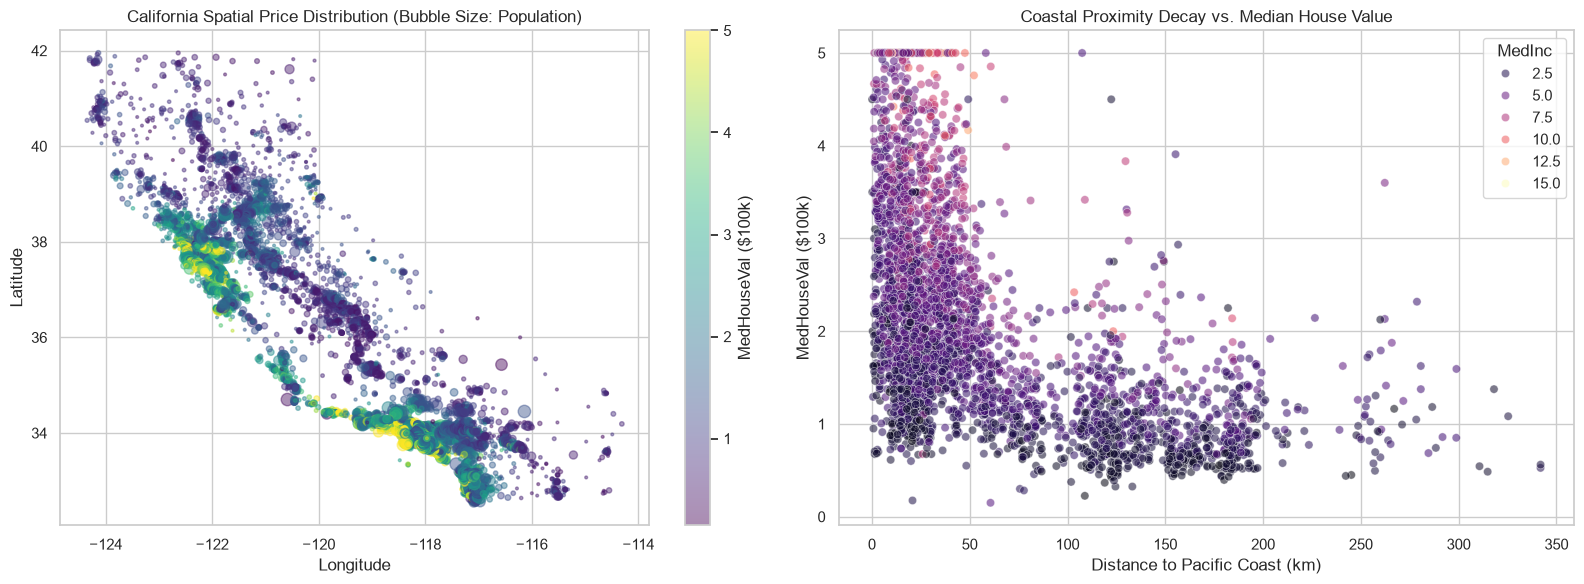

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sc = axes[0].scatter(
    df_eda["Longitude"],
    df_eda["Latitude"],
    c=df_eda["MedHouseVal"],
    cmap="viridis",
    alpha=0.45,
    s=np.clip(df_eda["Population"] / 100.0, 4, 80),
)
plt.colorbar(sc, ax=axes[0], label="MedHouseVal ($100k)")
axes[0].set_title("California Spatial Price Distribution (Bubble Size: Population)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")

sns.scatterplot(
    data=df_eda.sample(4000, random_state=42),
    x="MinDistToCoastKm",
    y="MedHouseVal",
    hue="MedInc",
    palette="magma",
    alpha=0.55,
    ax=axes[1],
)
axes[1].set_title("Coastal Proximity Decay vs. Median House Value")
axes[1].set_xlabel("Distance to Pacific Coast (km)")
axes[1].set_ylabel("MedHouseVal ($100k)")

plt.tight_layout()
plt.show()


### Summary & Architectural Decisions
Based on EDA evidence, our modeling pipeline (`src/features.py` and `src/modeling.py`) implements:
1. **Target-Decile Stratified 80/20 Split** prior to any fitting so skewed and top-coded values match across train and test.
2. **Leak-Free Geospatial & Domain Feature Engineering**: Haversine hub/coast distances, 30°/45° rotated coordinates (aligned to California's diagonal coastline), structural ratios, and **5-fold Out-of-Fold Haversine KNN Comparable Neighborhood Prices** (`SpatialCompsPrice`, `SpatialCompsPriceStd`).
3. **Multi-Model Benchmarking + Conformalized Quantile Regression (CQR)** in `02_Modeling.ipynb` to quantify both point accuracy and calibrated 90% prediction intervals.
